Matplotlib is building the font cache; this may take a moment.


               pickup             dropoff  passengers  distance  fare   tip  \
0 2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0  2.15   
1 2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0  0.00   
2 2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5  2.36   
3 2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0  6.15   
4 2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0  1.10   

   tolls  total   color      payment            pickup_zone  \
0    0.0  12.95  yellow  credit card        Lenox Hill West   
1    0.0   9.30  yellow         cash  Upper West Side South   
2    0.0  14.16  yellow  credit card          Alphabet City   
3    0.0  36.95  yellow  credit card              Hudson Sq   
4    0.0  13.40  yellow  credit card           Midtown East   

            dropoff_zone pickup_borough dropoff_borough  
0    UN/Turtle Bay South      Manhattan       Manhattan  
1  Upper West Side South      

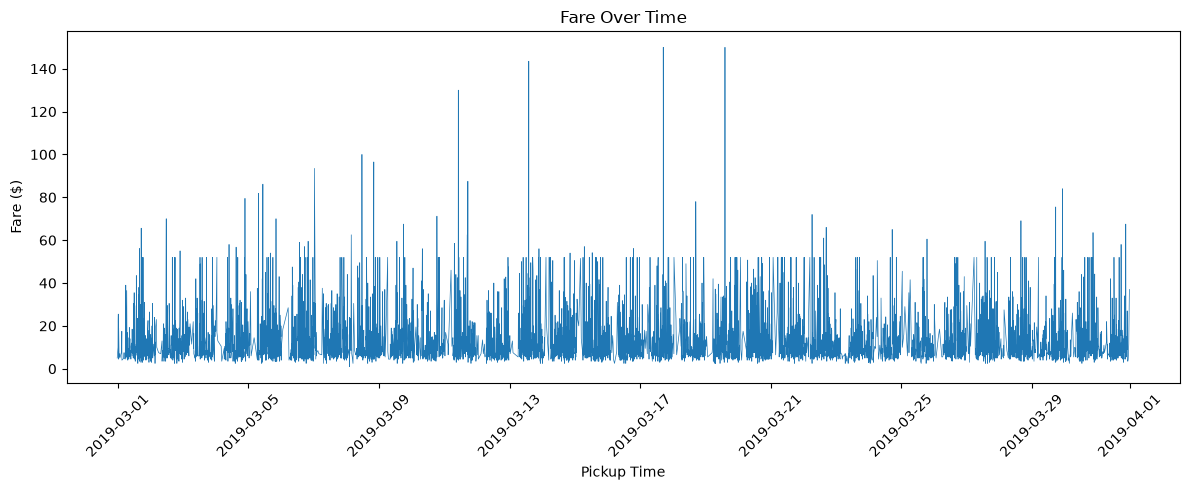

pickup_borough
Bronx         2078.91
Brooklyn      6327.48
Manhattan    58753.42
Queens       16382.06
Name: fare, dtype: float64


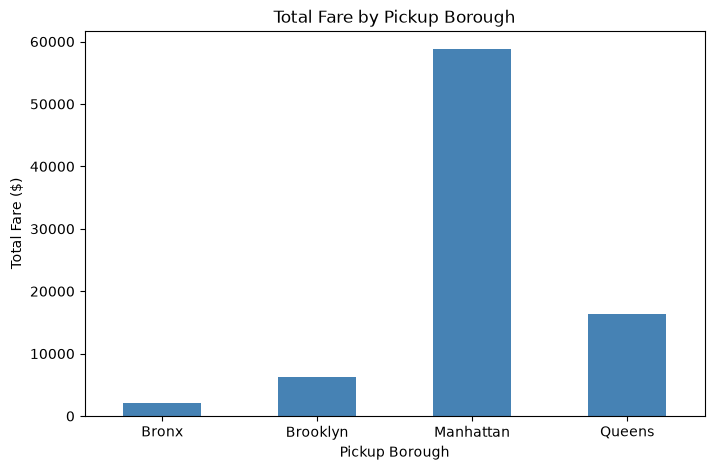

payment
credit card    4600
cash           1807
Name: count, dtype: int64


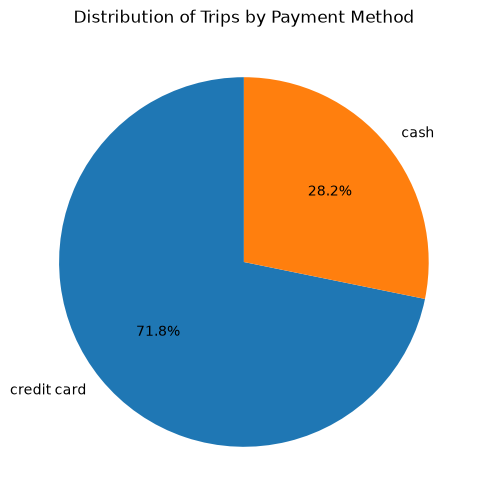

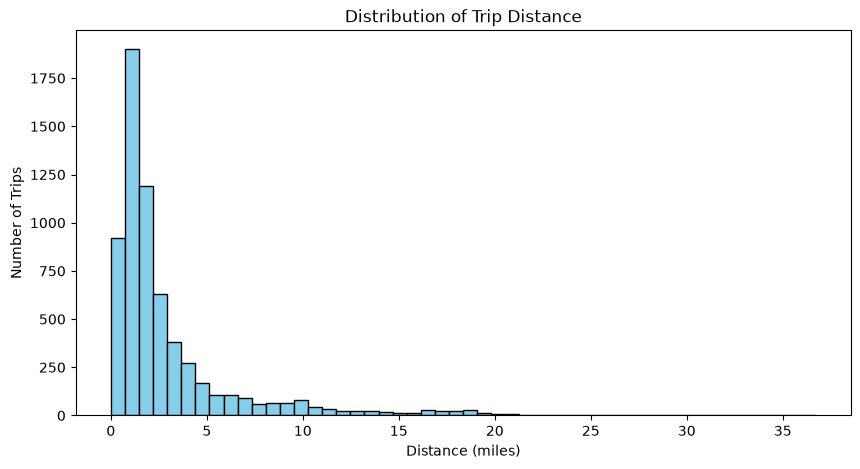

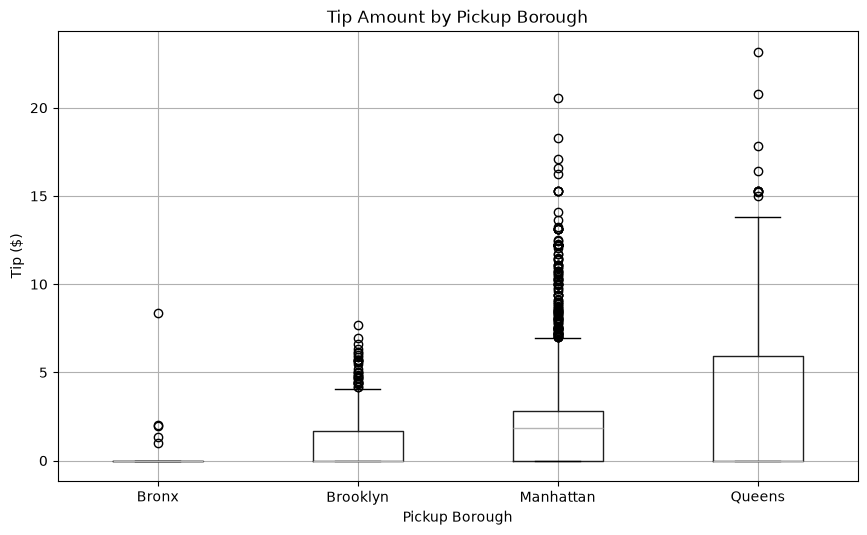

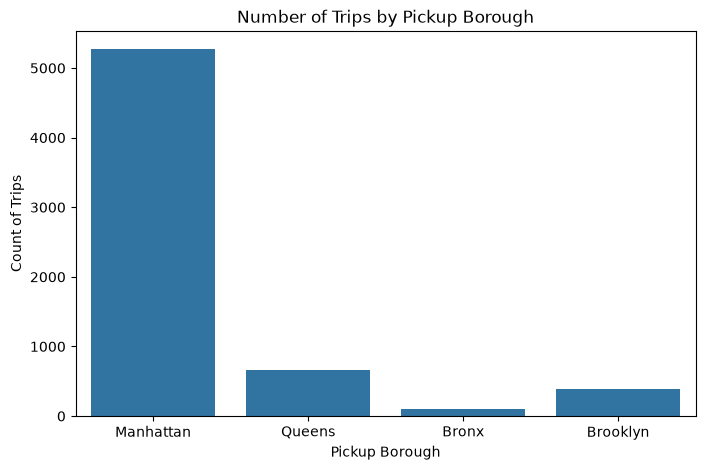

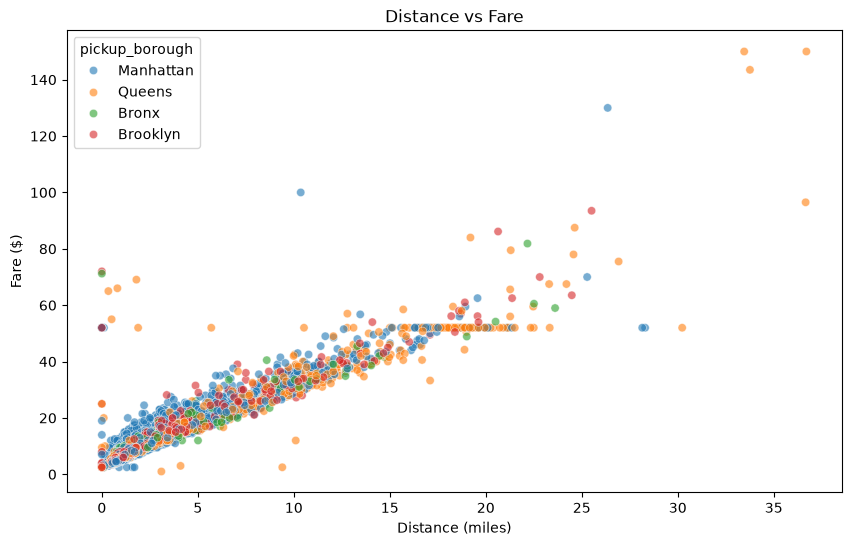

          distance      fare       tip     tolls     total
distance  1.000000  0.938783  0.463935  0.639339  0.924426
fare      0.938783  1.000000  0.469023  0.609828  0.973744
tip       0.463935  0.469023  1.000000  0.405218  0.631109
tolls     0.639339  0.609828  0.405218  1.000000  0.684341
total     0.924426  0.973744  0.631109  0.684341  1.000000


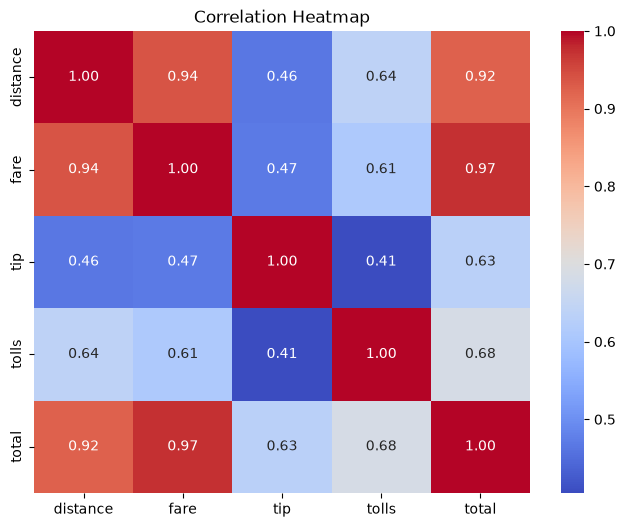

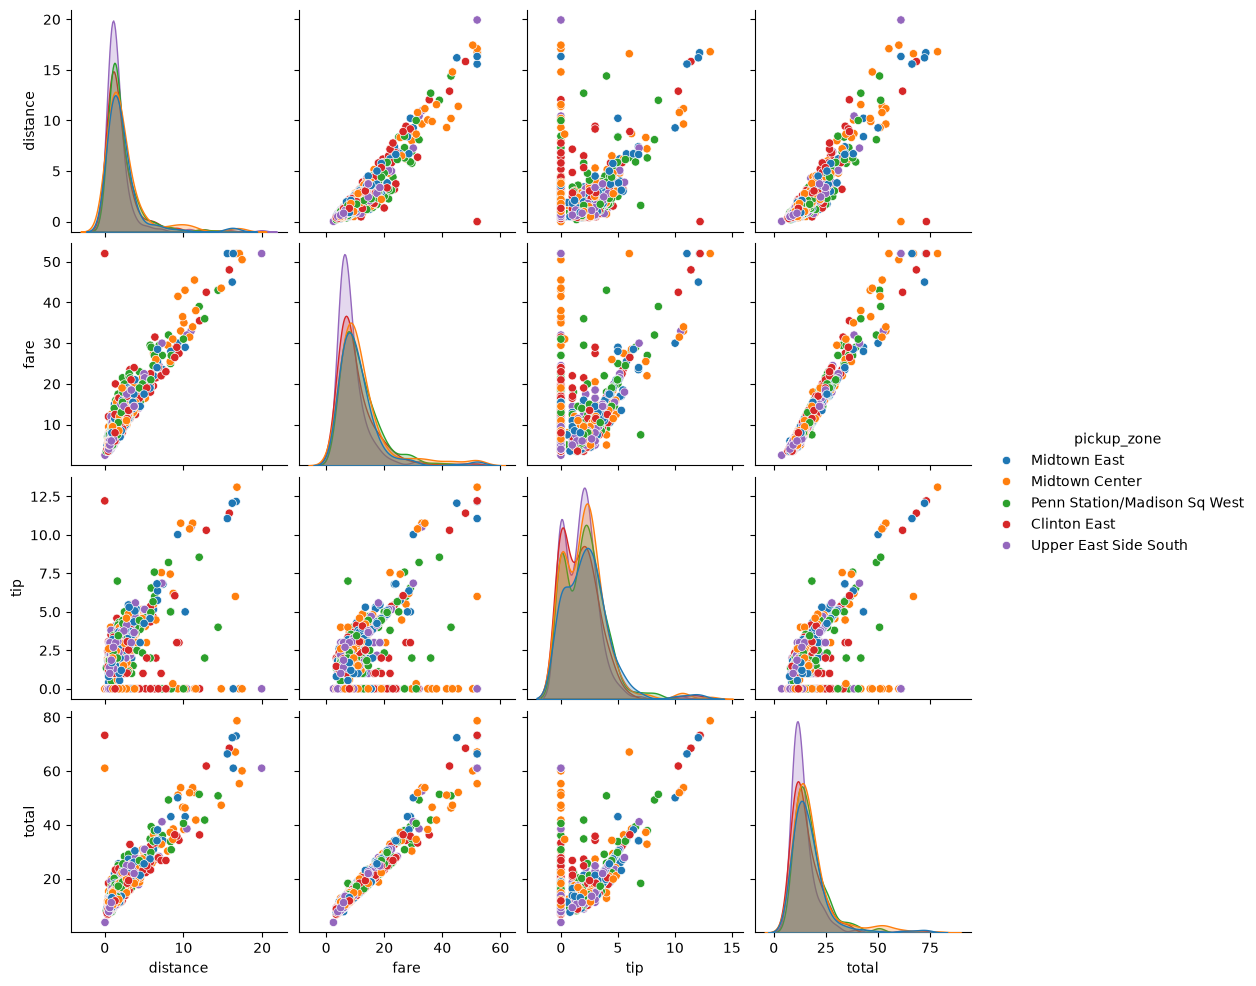

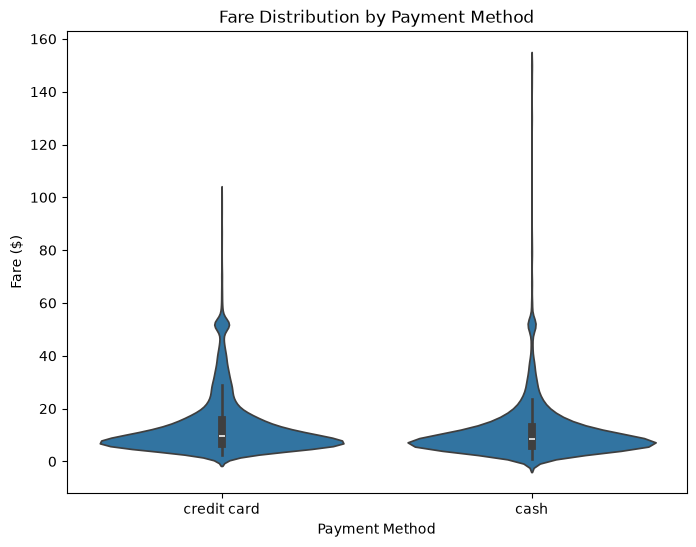

In [3]:
# ==================== 0) AUTO-INSTALL MISSING LIBRARIES ====================
import sys, subprocess, importlib
for pkg in ['pandas', 'matplotlib', 'seaborn']:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', pkg])

import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

# ==================== 1) LOAD DATASET ====================
try:
    df = sns.load_dataset("taxis")
except Exception:
    df = pd.read_csv("https://raw.githubusercontent.com/mwaskom/seaborn-data/master/taxis.csv")

print(df.head())
print("Shape:", df.shape)

# ==================== 2) HANDLING MISSING VALUES ====================
# Check missing values
print(df.isnull().sum())
print("Columns with missing data:", df.columns[df.isnull().any()].tolist())

# Numerical columns -> fill with median
num_cols = ['passengers', 'distance', 'fare', 'tip', 'tolls', 'total']
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

# Categorical columns -> fill with mode
df['payment'] = df['payment'].fillna(df['payment'].mode()[0])
df['dropoff_zone'] = df['dropoff_zone'].fillna(df['dropoff_zone'].mode()[0])
df['dropoff_borough'] = df['dropoff_borough'].fillna(df['dropoff_borough'].mode()[0])

# Critical columns -> remove rows
df = df.dropna(subset=['pickup_zone', 'pickup_borough']).copy()

print(df.isnull().sum())
print("Total missing values after cleaning:", df.isnull().sum().sum())
print("Shape after cleaning:", df.shape)

# ==================== 3) MATPLOTLIB / PANDAS PLOTS ====================

# Line Chart - Fare over time
df['pickup'] = pd.to_datetime(df['pickup'])
df_sorted = df.sort_values('pickup')
plt.figure(figsize=(12, 5))
plt.plot(df_sorted['pickup'], df_sorted['fare'], linewidth=0.5)
plt.title('Fare Over Time')
plt.xlabel('Pickup Time')
plt.ylabel('Fare ($)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Bar Chart - Total fare by pickup borough
borough_fare = df.groupby('pickup_borough')['fare'].sum()
print(borough_fare)
plt.figure(figsize=(8, 5))
borough_fare.plot(kind='bar', color='steelblue')
plt.title('Total Fare by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Total Fare ($)')
plt.xticks(rotation=0)
plt.show()

# Pie Chart - Trips by payment method
payment_counts = df['payment'].value_counts()
print(payment_counts)
plt.figure(figsize=(6, 6))
plt.pie(payment_counts, labels=payment_counts.index, autopct='%1.1f%%', startangle=90)
plt.title('Distribution of Trips by Payment Method')
plt.show()

# Histogram - Distance distribution
plt.figure(figsize=(10, 5))
plt.hist(df['distance'], bins=50, color='skyblue', edgecolor='black')
plt.title('Distribution of Trip Distance')
plt.xlabel('Distance (miles)')
plt.ylabel('Number of Trips')
plt.show()

# Box Plot - Tip by pickup borough
df.boxplot(column='tip', by='pickup_borough', figsize=(10, 6))
plt.title('Tip Amount by Pickup Borough')
plt.suptitle('')
plt.xlabel('Pickup Borough')
plt.ylabel('Tip ($)')
plt.show()

# ==================== 4) SEABORN PLOTS ====================

# Count Plot - Trips per pickup borough
plt.figure(figsize=(8, 5))
sns.countplot(x='pickup_borough', data=df)
plt.title('Number of Trips by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Count of Trips')
plt.show()

# Scatter Plot - Distance vs Fare, coloured by borough
plt.figure(figsize=(10, 6))
sns.scatterplot(x='distance', y='fare', hue='pickup_borough', data=df, alpha=0.6)
plt.title('Distance vs Fare')
plt.xlabel('Distance (miles)')
plt.ylabel('Fare ($)')
plt.show()

# Heatmap - Correlation matrix
corr = df[['distance', 'fare', 'tip', 'tolls', 'total']].corr()
print(corr)
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

# Pair Plot - coloured by pickup_zone (top 5 busiest zones)
top_zones = df['pickup_zone'].value_counts().head(5).index
df_top = df[df['pickup_zone'].isin(top_zones)]
sns.pairplot(df_top[['distance', 'fare', 'tip', 'total', 'pickup_zone']], hue='pickup_zone')
plt.show()

# Violin Plot - Fare by payment method
plt.figure(figsize=(8, 6))
sns.violinplot(x='payment', y='fare', data=df)
plt.title('Fare Distribution by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Fare ($)')
plt.show()